# Adult Mouse Brain Coronal Section

> - Author: Cao Qiang
> - Email: qiangcao2014@gmail.com
> - Created: 2025-11-17
> - Modified: 2025-11-17

---

> - [Adult Mouse Brain Coronal Section (Fresh Frozen)](https://www.10xgenomics.com/datasets/adult-mouse-brain-coronal-section-fresh-frozen-1-standard)
> - Organism: Mus musculus
> - Brain Coronal Section
> - 10X Visium Spatial Protocols (V1)
> - 2023-05-26

---

# Experimental Design

> - Visium Spatial Gene Expression Reagent Kits User Guide (CG000239 Rev F)
> - Dual Index set: SI-TT-E4
> - Slide: V10L08-332
> - Area: C1
> - H&E image
> - Illumina NovaSeq
> - Space Ranger v2.1.0

| Sample | Tissue | Organ | Strain | Gender | Age | Sample status | Disease status |
| - | - | - | - | - | - | - | - |
| Donor | Coronal Section | Brain | - | Male | Adult | Fresh Frozen | Healthy |

---

In [1]:
library(tidyverse)
# Load 10X Visium data
suppressPackageStartupMessages(library(VisiumIO))
suppressPackageStartupMessages(library(scran))
suppressPackageStartupMessages(library(scater))
# Quality control metrics visualization
suppressPackageStartupMessages(library(ggspavis))
suppressPackageStartupMessages(library(cowplot))

── Attaching core tidyverse packages ──────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────── tidyverse 2.0.0 ──
✔ dplyr     1.2.0     ✔ readr     2.1.6
✔ forcats   1.0.1     ✔ stringr   1.6.0
✔ ggplot2   4.0.2     ✔ tibble    3.3.1
✔ lubridate 1.9.5     ✔ tidyr     1.3.2
✔ purrr     1.2.1     
── Conflicts ────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────── tidyverse_conflicts() ──
✖ dplyr::filter() masks stats::filter()
✖ dplyr::lag()    masks stats::lag()
ℹ Use the conflicted package (<http://conflicted.r-lib.org/>) to force all conflicts to become errors


# 1. Data Import

In [2]:
data_dir <- "~/data1/single_cell_dataset/dataset_10xGenomics/Mm_Brain_VisiumV1_FF"

In [3]:
# dir.create(file.path(data_dir, "result"), 
#            recursive = TRUE, showWarnings = FALSE)
# dir.create(file.path(data_dir, "visualization"), 
#            recursive = TRUE, showWarnings = FALSE)

In [4]:
strna <- TENxVisium(
    spacerangerOut = file.path(data_dir, "outs"), 
    sample_id = "brain", processing = "raw", 
    format = "h5", images = "lowres") |> import()

In [5]:
strna

class: SpatialExperiment 
dim: 32285 4992 
metadata(2): resources spatialList
assays(1): counts
rownames(32285): ENSMUSG00000051951 ENSMUSG00000089699 ...
  ENSMUSG00000095019 ENSMUSG00000095041
rowData names(3): ID Symbol Type
colnames(4992): AAACAACGAATAGTTC-1 AAACAAGTATCTCCCA-1 ...
  TTGTTTGTATTACACG-1 TTGTTTGTGTAAATTC-1
colData names(4): in_tissue array_row array_col sample_id
reducedDimNames(0):
mainExpName: Gene Expression
altExpNames(0):
spatialCoords names(2) : pxl_col_in_fullres pxl_row_in_fullres
imgData names(4): sample_id image_id data scaleFactor

# 2. Quality Control

In [6]:
# subset to keep only spots over tissue
strna <- strna[, strna$in_tissue == 1]
dim(strna)

[1] 32285  2702

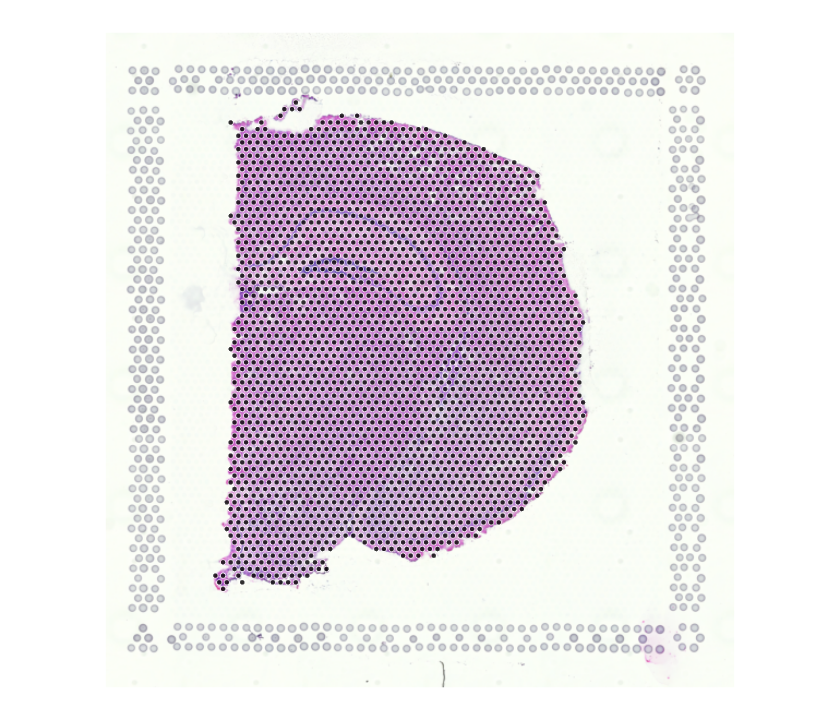

In [7]:
options(repr.plot.width = 7, repr.plot.height = 6)
plotVisium(strna, sample_id = "brain", image_id  = "lowres")

## 1). Filter Low-expression Genes

In [8]:
strna <- strna[rowSums(assay(strna) > 0) >= 3, ]
dim(strna)

[1] 19651  2702

## 2). Convert Ensembl Id to Symbol

In [9]:
message("Number of duplicated Symbols: ", sum(duplicated(rowData(strna)$Symbol)))

rowData(strna) |> as.data.frame() |> 
    group_by(Symbol) |> filter(n() > 1) |> 
    summarise(ID = paste(ID, collapse = "\t")) |> 
    ungroup() |> head()

Number of duplicated Symbols: 8



Symbol,ID
<chr>,<chr>
4930594M22Rik,ENSMUSG00000075463 ENSMUSG00000085423
Fam220a,ENSMUSG00000118332 ENSMUSG00000083012
Gm16364,ENSMUSG00000087014 ENSMUSG00000086915
Gm16499,ENSMUSG00000108175 ENSMUSG00000108255
Gm16701,ENSMUSG00000102548 ENSMUSG00000097823
Gm35438,ENSMUSG00000118209 ENSMUSG00000118020


In [10]:
aggregateFeatures <- function(obj, ids, use.assay.type = "counts") {
    
    counts <- sumCountsAcrossFeatures(
        obj, ids = ids, assay.type = "counts") |> 
        SparseArray::SparseArray(type = "integer") |> 
        DelayedArray::DelayedArray()

    rowdata <- rowData(obj) |> as.data.frame() |> 
        group_by(Symbol) |> 
        summarise(ID = paste(ID, collapse = ", "),
                  Type = dplyr::first(Type)) |> 
        ungroup() |> DataFrame()
    rownames(rowdata) <- rowdata$Symbol
    rowdata <- rowdata[rownames(counts), , drop = FALSE]

    obj <- obj[rep(1L, nrow(counts)), , drop = FALSE]
    rownames(obj) <- rownames(counts)
    rowData(obj) <- rowdata
    assay(obj, "counts", withDimnames = FALSE) <- counts

    return(obj)
}

In [11]:
# strna.temp1 <- scuttle::aggregateAcrossFeatures(
#     strna, ids = rowData(strna)$Symbol, use.assay.type = "counts")
strna <- aggregateFeatures(strna, ids = rowData(strna)$Symbol)

## 3). Calculate Metrics

In [12]:
calculate_qc_metrics <- function(
    obj, species = c("human", "mouse")) {
    
    species <- match.arg(species)
    
    # Mitochondrial genes
    mt_pattern <- "(?i)^MT-"
    # Ribosomal genes
    rp_pattern <- "(?i)^(MRP|RP[LS])"
    # Hemoglobin genes
    hb_pattern <- switch(
        species,
        human = "^(HBA1|HBA2|HBAP1|HBB|HBBP1|HBD|HBE1|HBG1|HBG2|HBM|HBQ1|HBZ|HBZP1)",
        mouse = "^(Hb[ab]-|Hbq1[ab])"
    )

    obj <- addPerCellQC(
        obj, subsets = list(
            mt = grepl(mt_pattern, rowData(obj)$Symbol), 
            rp = grepl(rp_pattern, rowData(obj)$Symbol), 
            hp = grepl(hb_pattern, rowData(obj)$Symbol)))

    return(obj)
}

In [13]:
strna <- calculate_qc_metrics(strna, species = "mouse")

## 2). Visualizate Metrics

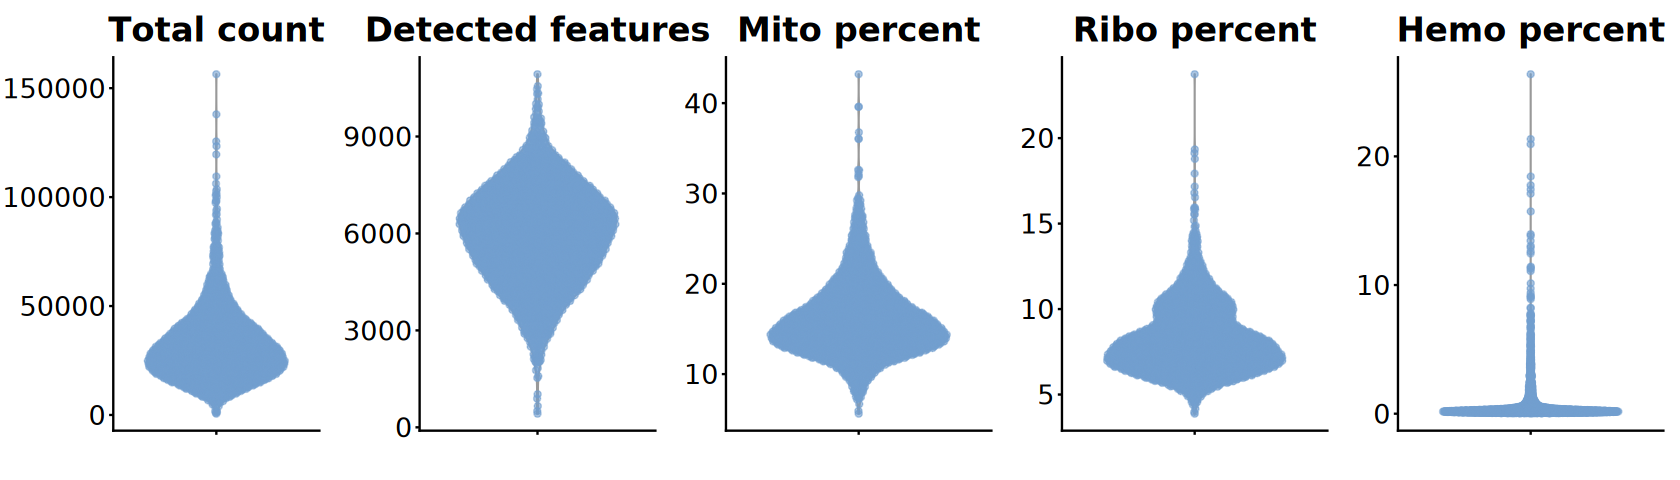

In [30]:
common_theme <- theme(
    plot.title = element_text(size = 20, hjust = 0.5), 
    legend.position = "none",
    axis.title = element_text(size = 18),
    axis.text = element_text(size = 16),
    plot.margin = margin(t = 10, r = 10, b = 10, l = 10))

plot_info <- tibble::tibble(
  y = c("sum", "detected", "subsets_mt_percent", "subsets_rp_percent", "subsets_hp_percent"),
  title = c("Total count", "Detected features", "Mito percent", "Ribo percent", "Hemo percent")
)

plots <- map2(
    plot_info$y, plot_info$title,
    ~ plotColData(strna, y = .x, color_by = "sample_id") + 
        labs(title = .y, x = NULL, y = NULL) + common_theme
)

options(repr.plot.width = 14, repr.plot.height = 4)
plot_grid(plotlist = plots, ncol = 5)

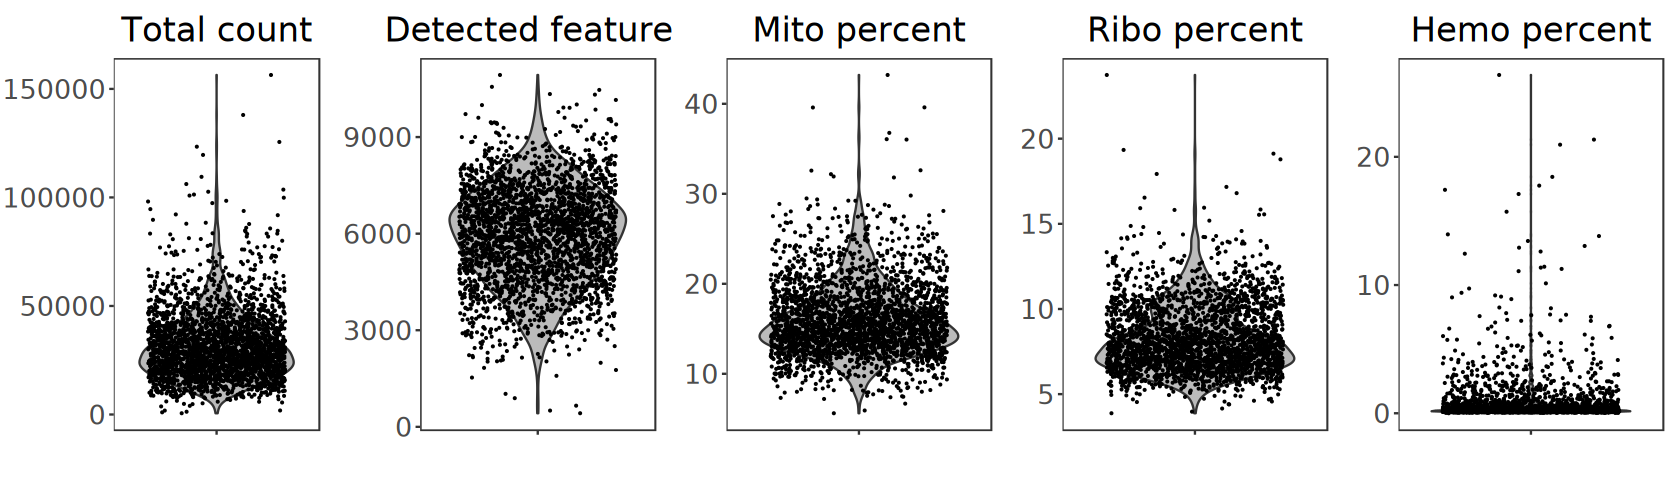

In [34]:
plots <- map2(
    plot_info$y, plot_info$title,
    ~ plotObsQC(strna, plot_type = "violin", x_metric = .x, 
                point_size = 0.1) + 
        labs(title = .y, x = NULL, y = NULL) + common_theme
)

options(repr.plot.width = 14, repr.plot.height = 4)
plot_grid(plotlist = plots, ncol = 5)

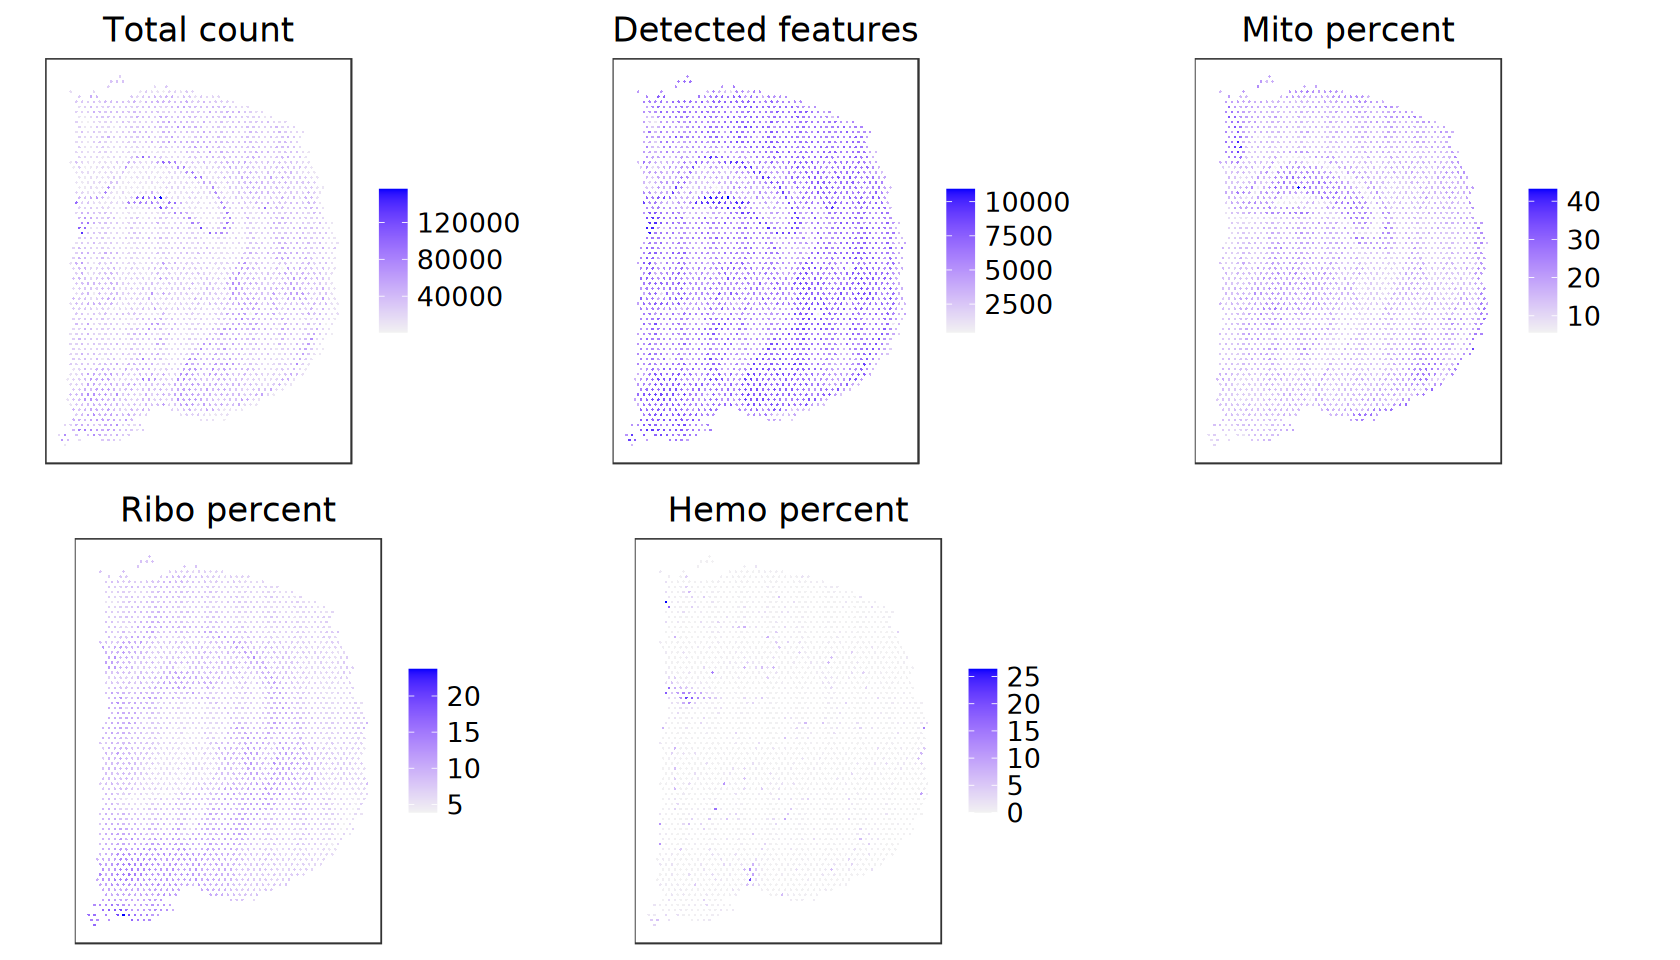

In [37]:
common_theme <- theme(
    plot.title = element_text(size = 20, hjust = 0.5), 
    legend.title = element_text(size = 18),
    legend.text = element_text(size = 16), 
    plot.margin = margin(t = 10, r = 10, b = 10, l = 10))

# check spatial pattern of discarded spots
plots <- map2(
    plot_info$y, plot_info$title,
    ~ plotCoords(strna, annotate = .x, point_size = 0.1) + 
        labs(title = .y, x = NULL, y = NULL) + common_theme
)

options(repr.plot.width = 14, repr.plot.height = 8)
plot_grid(plotlist = plots, ncol = 3)

## 3). Filtering Low-quality Spots

In [18]:
strna$qc_detected <- strna$detected < 500
strna$qc_libSize <- strna$sum < 1000
strna$qc_mitoProp <- strna$subsets_mt_percent > 30

sapply(colData(strna)[grep("^qc", names(colData(strna)))], table)

,qc_detected,qc_libSize,qc_mitoProp
FALSE,2701,2701,2691
TRUE,1,1,11


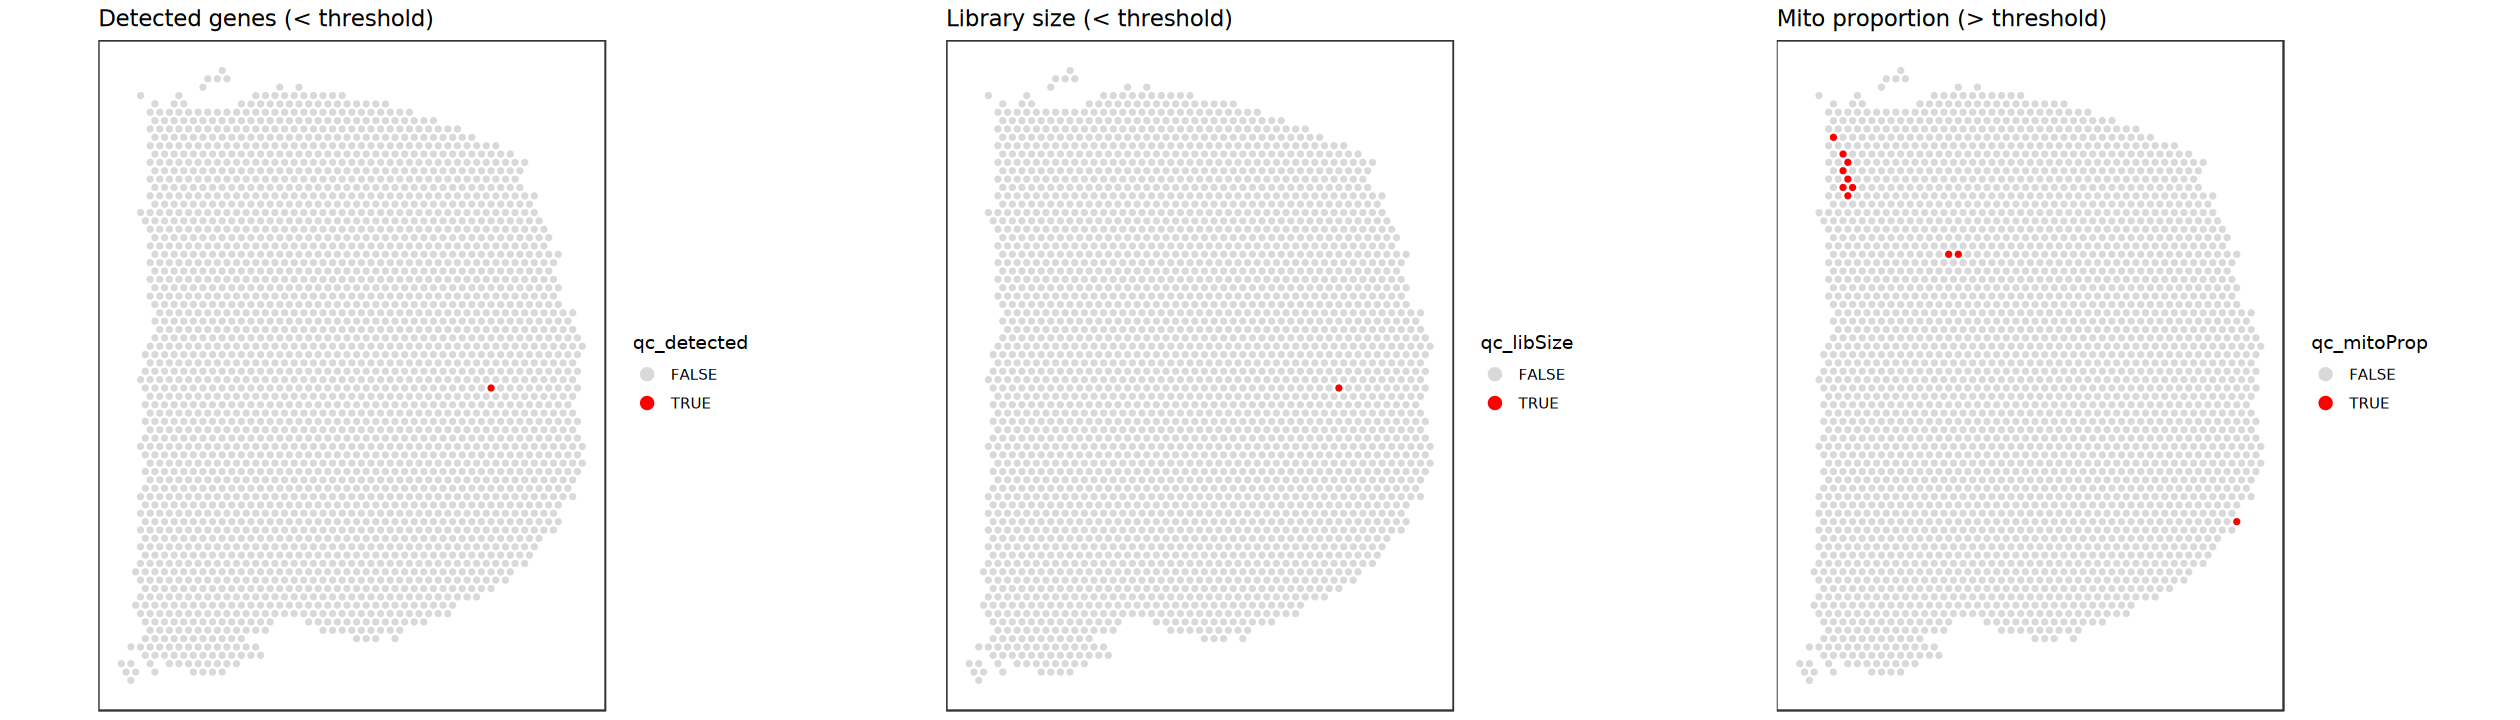

In [19]:
# plot spatial distributions of discarded spots
p1 <- plotObsQC(
    strna, plot_type = "spot", annotate = "qc_detected", 
    point_size = 1) +
    ggtitle("Detected genes (< threshold)")
p2 <- plotObsQC(
    strna, plot_type = "spot", annotate = "qc_libSize", 
    point_size = 1) + 
    ggtitle("Library size (< threshold)")
p3 <- plotObsQC(
    strna, plot_type = "spot", annotate = "qc_mitoProp", 
    point_size = 1) + 
    ggtitle("Mito proportion (> threshold)")

options(repr.plot.width = 21, repr.plot.height = 6)
plot_grid(p1, p2, p3, ncol = 3)

In [20]:
discard <- strna$qc_detected | strna$qc_libSize | strna$qc_mitoProp
strna <- strna[, !discard]
dim(strna)

[1] 19643  2690

## Histological artifact detection

In [21]:
library(SpotSweeper)

## Assessing spot quality via cell segmentation

In [22]:
strna

class: SpatialExperiment 
dim: 19643 2690 
metadata(2): resources spatialList
assays(1): counts
rownames(19643): 0610005C13Rik 0610009B22Rik ... Zzef1 Zzz3
rowData names(6): Symbol ID ... subsets_rp subsets_hp
colnames(2690): AAACAAGTATCTCCCA-1 AAACAATCTACTAGCA-1 ...
  TTGTTTCCATACAACT-1 TTGTTTGTGTAAATTC-1
colData names(19): in_tissue array_row ... qc_libSize qc_mitoProp
reducedDimNames(0):
mainExpName: Gene Expression
altExpNames(0):
spatialCoords names(2) : pxl_col_in_fullres pxl_row_in_fullres
imgData names(4): sample_id image_id data scaleFactor

# 3. Normalization

## a). LogNormalize

In [23]:
# calculate library size factors
strna <- scuttle::computeLibraryFactors(strna)

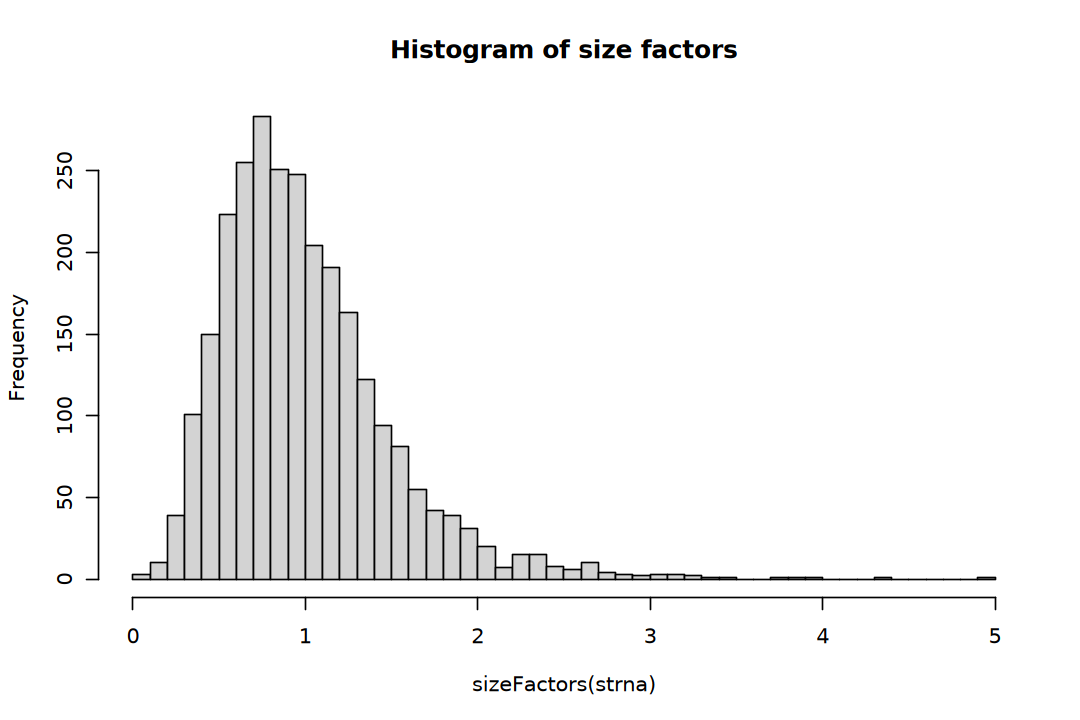

In [24]:
options(repr.plot.width = 9, repr.plot.height = 6)
hist(sizeFactors(strna), breaks = 50, main = "Histogram of size factors")

In [25]:
# calculate logcounts and store in new assay
strna <- scuttle::logNormCounts(strna, name = "logNorm")

## b). Spatially-aware normalization

In [26]:
library(SpaNorm)

In [27]:
strna <- SpaNorm(strna, verbose = FALSE)

In [28]:
strna

class: SpatialExperiment 
dim: 19643 2690 
metadata(3): resources spatialList SpaNorm
assays(3): counts logNorm logcounts
rownames(19643): 0610005C13Rik 0610009B22Rik ... Zzef1 Zzz3
rowData names(6): Symbol ID ... subsets_rp subsets_hp
colnames(2690): AAACAAGTATCTCCCA-1 AAACAATCTACTAGCA-1 ...
  TTGTTTCCATACAACT-1 TTGTTTGTGTAAATTC-1
colData names(20): in_tissue array_row ... qc_mitoProp sizeFactor
reducedDimNames(0):
mainExpName: Gene Expression
altExpNames(0):
spatialCoords names(2) : pxl_col_in_fullres pxl_row_in_fullres
imgData names(4): sample_id image_id data scaleFactor

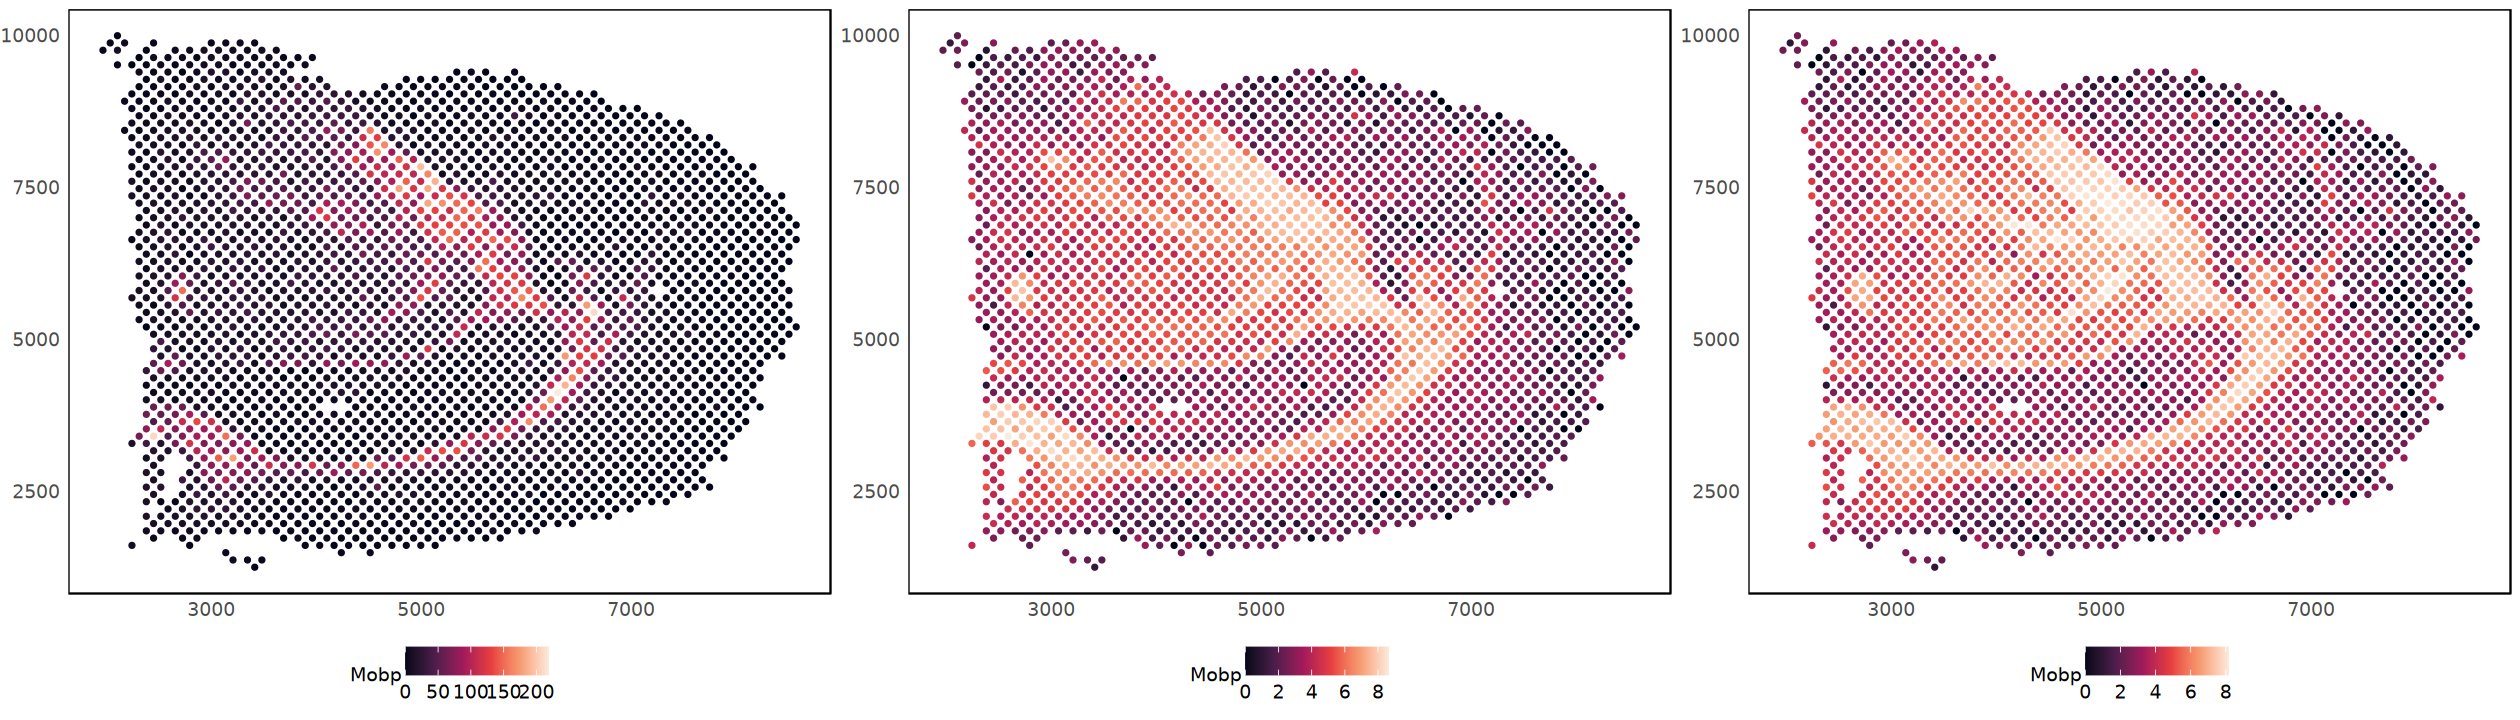

In [30]:
p1 <- plotSpatial(
    strna, colour = Mobp, what = "expression",
    assay = "counts", size = 1) + 
    scale_colour_viridis_c(option = "F")
p2 <- plotSpatial(
    strna, colour = Mobp, what = "expression",
    assay = "logNorm", size = 1) + 
    scale_colour_viridis_c(option = "F")
p3 <- plotSpatial(
    strna, colour = Mobp, what = "expression",
    assay = "logcounts", size = 1) + 
    scale_colour_viridis_c(option = "F")

options(repr.plot.width = 21, repr.plot.height = 6)
plot_grid(p1, p2, p3, ncol = 3)

# Feature selection

## a). Highly variable genes (HVGs)

In [36]:
# fit mean-variance relationship
dec <- scran::modelGeneVar(strna)
# select top HVGs
sel <- scran::getTopHVGs(dec, prop = 0.1)

Warning message in regularize.values(x, y, ties, missing(ties), na.rm = na.rm):
“collapsing to unique 'x' values”


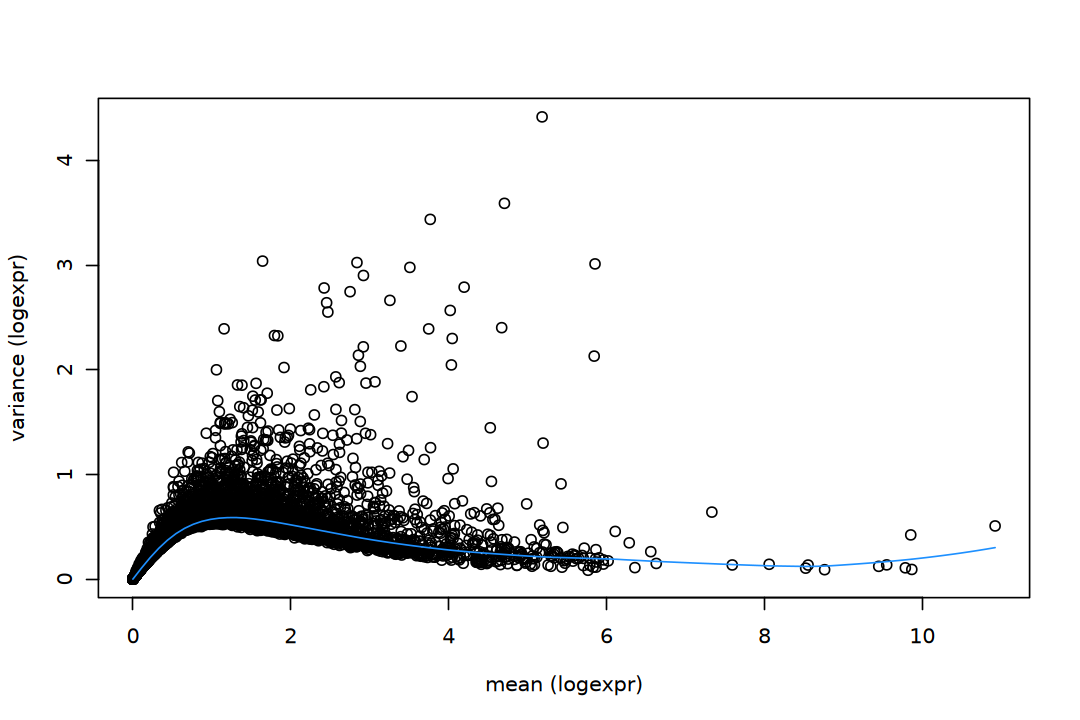

In [38]:
options(repr.plot.width = 9, repr.plot.height = 6)
plot(dec$mean, dec$total, xlab = "mean (logexpr)", ylab = "variance (logexpr)")
curve(metadata(dec)$trend(x), add = TRUE, col = "dodgerblue")

## b). Spatially variable genes

# 5. Linear Dimensionality Reduction

In [39]:
strna <- runPCA(strna, subset_row = sel)

# 8. Non-linear Dimensionality Reduction

In [40]:
strna <- runUMAP(strna, dimred = "PCA")

# 9. Clustering

In [41]:
library(BayesSpace)

In [42]:
# run BayesSpace clustering
.strna <- spatialPreprocess(strna, skip.PCA = TRUE)
.strna <- spatialCluster(.strna, nrep = 1000, burn.in = 100, q = 10, d = 20)

Neighbors were identified for 2689 out of 2690 spots.

Fitting model...

Calculating labels using iterations 101 through 1000.



In [43]:
# cluster labels
table(strna$BayesSpace <- factor(.strna$spatial.cluster))


  1   2   3   4   5   6   7   8   9  10 
218 260  85 458 409 265 382 151 248 214 

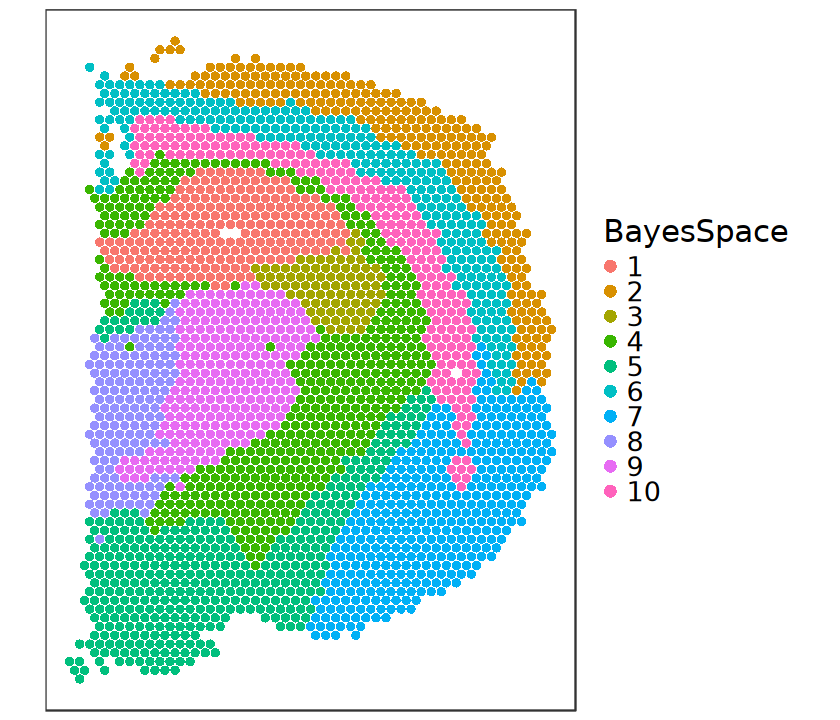

In [48]:
options(repr.plot.width = 7, repr.plot.height = 6)
plotCoords(strna, annotate = "BayesSpace", point_size = 2) + 
    theme(legend.title = element_text(size = 18), 
          legend.text = element_text(size = 16),
          legend.key.size = unit(0, "lines"))

# 10. Cluster Biomarkers